# 12 — Week 4: validation analysis across all models (ramp errors, Diebold–Mariano, ramp event, costs)

Run **after notebook 11**. Uses only validation predictions already on disk (no training, no test data):
notebooks 07 / 08 (baselines, statistical, LightGBM), 09 (LSTM, GRU) and 11 (N-HiTS, PatchTST, DLinear, NLinear,
univariate GRU). Multi-seed models are represented by **seed 0** in the DM tests, the ramp table and the figures;
the benchmark table keeps mean ± sd over seeds. Helper module: `src/evaluation/compare.py`.
Outputs: `reports/week4/` (CSV + JSON) and `reports/figures/week4/`.

In [1]:
# Cell 1: setup and inputs
import sys, json, time
from pathlib import Path
import numpy as np
import polars as pl
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))
from evaluation import metrics as M
from evaluation import compare as C

REP = ROOT / "reports" / "week4"
FIG = ROOT / "reports" / "figures" / "week4"
REP.mkdir(parents=True, exist_ok=True); FIG.mkdir(parents=True, exist_ok=True)
HORIZONS = (1, 5, 15)
pl.Config.set_tbl_rows(80); pl.Config.set_tbl_cols(24); pl.Config.set_tbl_width_chars(250)

md = pl.read_parquet(ROOT / "data" / "processed" / "model_dataset.parquet")
meta = json.loads((ROOT / "data" / "processed" / "model_dataset_meta.json").read_text())
BENCH_F = REP / "benchmark_val_week4_nf.csv"
assert BENCH_F.exists(), "run notebook 11 first (it writes reports/week4/benchmark_val_week4_nf.csv)"
bench = pl.read_csv(BENCH_F)
FAMILY = dict(zip(bench["model"].to_list(), bench["family"].to_list()))
print(f"dataset rows {md.height:,} | benchmark rows {bench.height} | models {bench['model'].n_unique()}")
SUMMARY = {"created": time.strftime("%Y-%m-%d %H:%M:%S"), "split": "val", "seed_for_pairwise": 0}


dataset rows 303,840 | benchmark rows 54 | models 18


In [2]:
# Cell 2: all validation predictions in one table, aligned on common origins per horizon (needs cell 1)
pred = C.load_predictions(ROOT, seed=0)
al, cov = C.align(pred)
al = C.add_labels(al, md)
print(cov.pivot(on="h", index="model", values="n").sort("model"))
nc = cov.group_by("h").agg(pl.col("n_common").first(), pl.col("n").min().alias("n_min"), pl.col("n").max().alias("n_max"))
print(nc.sort("h"))
lost = nc.with_columns((1 - pl.col("n_common") / pl.col("n_max")).alias("share_dropped"))
assert lost["share_dropped"].max() < 0.01, "models disagree on more than 1% of origins: send this output"
print("models in the aligned table:", sorted(al["model"].unique().to_list()))
SUMMARY["coverage"] = nc.to_dicts()


shape: (18, 4)
┌───────────────────┬───────┬───────┬───────┐
│ model             ┆ 1     ┆ 5     ┆ 15    │
│ ---               ┆ ---   ┆ ---   ┆ ---   │
│ str               ┆ u32   ┆ u32   ┆ u32   │
╞═══════════════════╪═══════╪═══════╪═══════╡
│ ar_lags           ┆ 42575 ┆ 42567 ┆ 42547 │
│ ar_lags_cal       ┆ 42575 ┆ 42567 ┆ 42547 │
│ ar_lags_cal_cov   ┆ 42575 ┆ 42567 ┆ 42547 │
│ auto_arima        ┆ 42575 ┆ 42567 ┆ 42547 │
│ auto_ets          ┆ 42575 ┆ 42567 ┆ 42547 │
│ dlinear           ┆ 42575 ┆ 42567 ┆ 42547 │
│ gru               ┆ 42575 ┆ 42567 ┆ 42547 │
│ gru_uni           ┆ 42575 ┆ 42567 ┆ 42547 │
│ lightgbm          ┆ 42575 ┆ 42567 ┆ 42547 │
│ lightgbm_cov      ┆ 42575 ┆ 42567 ┆ 42547 │
│ lstm              ┆ 42575 ┆ 42567 ┆ 42547 │
│ nhits             ┆ 42575 ┆ 42567 ┆ 42547 │
│ nlinear           ┆ 42575 ┆ 42567 ┆ 42547 │
│ patchtst          ┆ 42575 ┆ 42567 ┆ 42547 │
│ pers_mod5_rolling ┆ 42575 ┆ 42567 ┆ 42547 │
│ pers_mod5_static  ┆ 42575 ┆ 42567 ┆ 42547 │
│ persistence      

In [3]:
# Cell 3: cost table: parameters, training and inference time (networks; seeds averaged) (needs cell 1)
rows = []
for group, pat in (("week3_rnn", None), ("week4_nf", None)):
    gdir = ROOT / "experiments" / group
    if not gdir.exists():
        continue
    for d in sorted(gdir.iterdir()):
        f = d / "metrics.json"
        if not f.exists():
            continue
        r = json.loads(f.read_text())
        name = d.name.rsplit("_s", 1)[0].replace("_local", "")
        rows.append({"group": group, "model": name, "seed": int(d.name.rsplit("_s", 1)[1]),
                     "n_params": r["info"]["n_params"], "train_s": r["info"]["train_s"],
                     "epochs_run": r["info"]["epochs_run"], "best_epoch": r["info"]["best_epoch"],
                     "s_per_epoch": r["info"]["train_s"] / max(r["info"]["epochs_run"], 1),
                     "infer_ms_per_sample": r["metrics"].get("infer_ms_per_sample"),
                     "device": r["info"].get("device", "cpu"),
                     "inputs": "power + calendar" if group == "week3_rnn" else "power only"})
COST = (pl.DataFrame(rows).group_by("group", "model", "inputs", "device")
          .agg(pl.len().alias("seeds"), pl.col("n_params").first(), pl.col("train_s").mean().round(0),
               pl.col("s_per_epoch").mean().round(1), pl.col("best_epoch").mean().round(1),
               pl.col("infer_ms_per_sample").mean().round(4))
          .sort("n_params"))
print(COST)
COST.write_csv(REP / "cost_networks.csv")
print("note: LightGBM, AR and state-space costs are in notebooks 07/08 (not parameter-comparable); "
      "devices differ (CPU vs MPS), so times are indicative only.")
SUMMARY["cost"] = COST.to_dicts()


shape: (8, 10)
┌───────────┬─────────────┬──────────────────┬────────┬───────┬──────────┬─────────┬─────────────┬────────────┬─────────────────────┐
│ group     ┆ model       ┆ inputs           ┆ device ┆ seeds ┆ n_params ┆ train_s ┆ s_per_epoch ┆ best_epoch ┆ infer_ms_per_sample │
│ ---       ┆ ---         ┆ ---              ┆ ---    ┆ ---   ┆ ---      ┆ ---     ┆ ---         ┆ ---        ┆ ---                 │
│ str       ┆ str         ┆ str              ┆ str    ┆ u32   ┆ i64      ┆ f64     ┆ f64         ┆ f64        ┆ f64                 │
╞═══════════╪═════════════╪══════════════════╪════════╪═══════╪══════════╪═════════╪═════════════╪════════════╪═════════════════════╡
│ week4_nf  ┆ nlinear     ┆ power only       ┆ cpu    ┆ 3     ┆ 915      ┆ 1.0     ┆ 0.2         ┆ 3.3        ┆ 0.0004              │
│ week4_nf  ┆ dlinear     ┆ power only       ┆ cpu    ┆ 3     ┆ 1830     ┆ 1.0     ┆ 0.3         ┆ 2.0        ┆ 0.0006              │
│ week4_nf  ┆ gru_uni     ┆ power only       ┆ 

In [4]:
# Cell 4: ramp-error analysis on aligned validation origins (needs cell 2)
RB = C.ramp_breakdown(al, meta["thresholds"])
RB.write_csv(REP / "ramp_breakdown_val.csv")
for h in HORIZONS:
    t = RB.filter(pl.col("h") == h).sort("MAE_ramp")
    r0 = t.row(0, named=True)
    print(f"\n=== h = {h} min | ramp steps {r0['n_ramp']:,} of {r0['n']:,} | severe (p99) {r0['n_severe']:,} ===")
    print(t.select("model", pl.col("MAE_normal").round(4), pl.col("MAE_ramp").round(3), pl.col("MAE_ramp_up").round(3),
                   pl.col("MAE_ramp_down").round(3), pl.col("MAE_severe").round(3), pl.col("ramp_to_normal").round(1),
                   pl.col("skill_normal").round(3), pl.col("skill_ramp").round(3), pl.col("skill_severe").round(3),
                   pl.col("ramp_recall").round(3), pl.col("ramp_F1").round(3)))
SUMMARY["ramp_breakdown"] = RB.to_dicts()



=== h = 1 min | ramp steps 1,903 of 42,575 | severe (p99) 440 ===
shape: (18, 12)
┌───────────────────┬────────────┬──────────┬─────────────┬───────────────┬────────────┬────────────────┬──────────────┬────────────┬──────────────┬─────────────┬─────────┐
│ model             ┆ MAE_normal ┆ MAE_ramp ┆ MAE_ramp_up ┆ MAE_ramp_down ┆ MAE_severe ┆ ramp_to_normal ┆ skill_normal ┆ skill_ramp ┆ skill_severe ┆ ramp_recall ┆ ramp_F1 │
│ ---               ┆ ---        ┆ ---      ┆ ---         ┆ ---           ┆ ---        ┆ ---            ┆ ---          ┆ ---        ┆ ---          ┆ ---         ┆ ---     │
│ str               ┆ f64        ┆ f64      ┆ f64         ┆ f64           ┆ f64        ┆ f64            ┆ f64          ┆ f64        ┆ f64          ┆ f64         ┆ f64     │
╞═══════════════════╪════════════╪══════════╪═════════════╪═══════════════╪════════════╪════════════════╪══════════════╪════════════╪══════════════╪═════════════╪═════════╡
│ lightgbm_cov      ┆ 0.1998     ┆ 1.276    ┆ 1.034 

In [5]:
# Cell 5: Diebold-Mariano between the four best models per horizon and persistence, Holm-corrected (needs cell 2)
avail = set(al["model"].unique().to_list())
TOP = {}
for h in HORIZONS:
    t = bench.filter((pl.col("h") == h) & pl.col("model").is_in(sorted(avail)) & (pl.col("model") != "persistence"))
    TOP[h] = t.sort("MAE_mean")["model"].head(4).to_list() + ["persistence"]
    print(f"h={h}: compared {TOP[h]}")
DM = C.dm_pairs(al, TOP, lag=60)
DM.write_csv(REP / "dm_pairs_val.csv")
print(DM.select("h", "model_a", "model_b", pl.col("MAE_a").round(4), pl.col("MAE_b").round(4),
                pl.col("DM_stat").round(2), pl.col("DM_p").round(5), pl.col("DM_p_holm").round(5), "better",
                "significant_5pct"))
print("DM on absolute errors, Newey-West lag 60; origins with gaps treated as one sequence (approximation).")
SUMMARY["dm_top"] = {str(k): v for k, v in TOP.items()}
SUMMARY["dm"] = DM.to_dicts()


h=1: compared ['lightgbm_cov', 'lightgbm', 'patchtst', 'gru', 'persistence']
h=5: compared ['lightgbm_cov', 'lightgbm', 'patchtst', 'lstm', 'persistence']
h=15: compared ['lightgbm_cov', 'lightgbm', 'nhits', 'patchtst', 'persistence']
shape: (30, 10)
┌─────┬──────────────┬─────────────┬────────┬────────┬─────────┬─────────┬───────────┬──────────────┬──────────────────┐
│ h   ┆ model_a      ┆ model_b     ┆ MAE_a  ┆ MAE_b  ┆ DM_stat ┆ DM_p    ┆ DM_p_holm ┆ better       ┆ significant_5pct │
│ --- ┆ ---          ┆ ---         ┆ ---    ┆ ---    ┆ ---     ┆ ---     ┆ ---       ┆ ---          ┆ ---              │
│ i64 ┆ str          ┆ str         ┆ f64    ┆ f64    ┆ f64     ┆ f64     ┆ f64       ┆ str          ┆ bool             │
╞═════╪══════════════╪═════════════╪════════╪════════╪═════════╪═════════╪═══════════╪══════════════╪══════════════════╡
│ 1   ┆ lightgbm_cov ┆ lightgbm    ┆ 0.2465 ┆ 0.2491 ┆ -2.81   ┆ 0.00489 ┆ 0.00978   ┆ lightgbm_cov ┆ true             │
│ 1   ┆ lightgbm_cov ┆ 

event origin 2021-08-23 12:25:00 (index 248425) | |dP|/L24 at h=5 = 0.776 | models ['persistence', 'ar_lags_cal_cov', 'lightgbm_cov', 'patchtst']


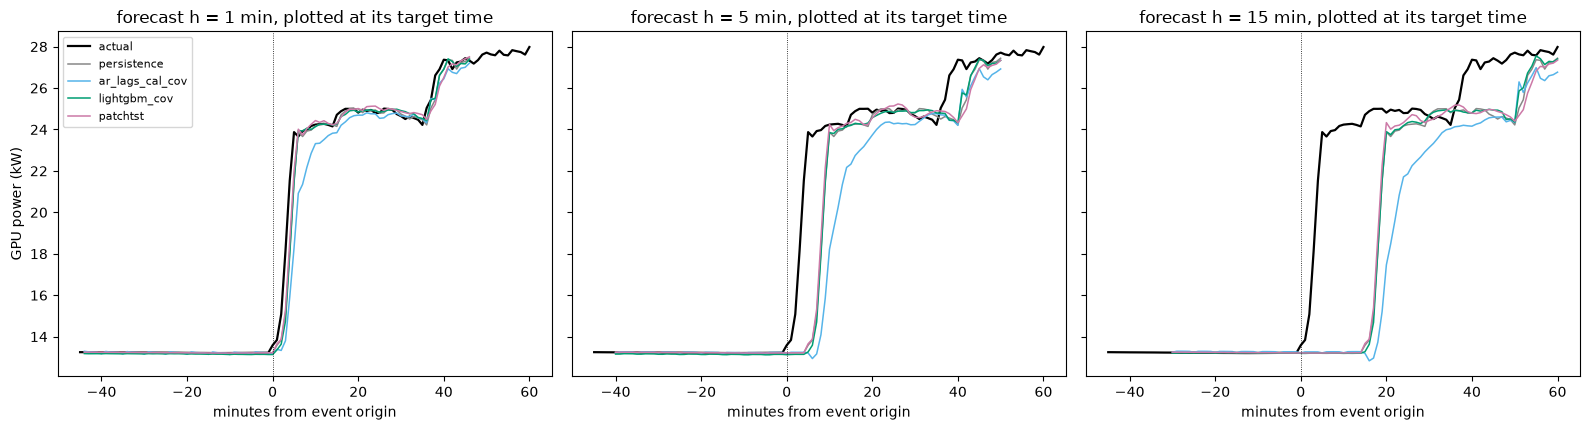

saved reports/figures/week4/01_ramp_event_val.png


In [6]:
# Cell 6: figure: one severe ramp in validation, forecasts of four models at h = 1, 5, 15 (needs cells 2, 5)
t0, rel = C.pick_event(md, h=5, half=45)
assert t0 is not None, "no severe validation ramp with a mostly valid window found"
ep0 = int(md["minute_epoch"][t0])
best_of = {}
for fam in ("linear", "ML", "deep"):
    t = bench.filter((pl.col("h") == 5) & (pl.col("family") == fam) & pl.col("model").is_in(sorted(avail))).sort("MAE_mean")
    if t.height:
        best_of[fam] = t["model"][0]
SHOW = ["persistence"] + list(best_of.values())
print(f"event origin {pl.from_epoch(pl.Series([ep0]), time_unit='s')[0]} (index {t0}) | |dP|/L24 at h=5 = {rel:.3f} | models {SHOW}")
half = 45
lo, hi = ep0 - half * 60, ep0 + (half + 15) * 60
act = md.filter((pl.col("minute_epoch") >= lo) & (pl.col("minute_epoch") <= hi)).select("minute_epoch", "P_kW", "valid")
colors = {"persistence": "#888888", best_of.get("linear"): "#56b4e9", best_of.get("ML"): "#009e73",
          best_of.get("deep"): "#cc79a7"}
fig, axes = plt.subplots(1, 3, figsize=(16, 4.4), sharey=True)
for ax, h in zip(axes, HORIZONS):
    x = (act["minute_epoch"].to_numpy() - ep0) / 60
    ax.plot(x, np.where(act["valid"].to_numpy(), act["P_kW"].fill_null(np.nan).to_numpy(), np.nan), color="k", lw=1.6,
            label="actual")
    for m in SHOW:
        g = pred.filter((pl.col("model") == m) & (pl.col("h") == h) & (pl.col("minute_epoch") >= lo) &
                        (pl.col("minute_epoch") <= ep0 + half * 60)).sort("minute_epoch")
        ax.plot((g["minute_epoch"].to_numpy() + 60 * h - ep0) / 60, g["yhat"].to_numpy(), lw=1.1,
                color=colors.get(m, None), label=f"{m}")
    ax.axvline(0, color="k", lw=0.6, ls=":")
    ax.set_title(f"forecast h = {h} min, plotted at its target time"); ax.set_xlabel("minutes from event origin")
axes[0].set_ylabel("GPU power (kW)"); axes[0].legend(fontsize=8)
fig.tight_layout(); fig.savefig(FIG / "01_ramp_event_val.png", dpi=140); plt.show()
print("saved", (FIG / "01_ramp_event_val.png").relative_to(ROOT))
SUMMARY["ramp_event"] = {"origin_epoch": ep0, "index": t0, "rel_change_h5": rel, "models": SHOW}


In [7]:
# Cell 7: weekly skill at h = 1 with and without five-minute-dip targets (tests the Week 3 hypothesis) (needs cell 5)
WK = C.weekly_skill_mod5(al, TOP[1][:3], h=1)
WK.write_csv(REP / "weekly_skill_mod5_val.csv")
piv = (WK.with_columns(pl.col("skill_MAE").round(3), (pl.col("model") + " | " + pl.col("targets")).alias("col"))
         .pivot(on="col", index="block_start", values="skill_MAE").sort("block_start"))
print(piv)
print("If the week of 16 Aug turns positive (or much less negative) without mod-0 targets, the Week 3 hypothesis "
      "(over-correction of the five-minute dip) is supported; otherwise it is not.")
SUMMARY["weekly_mod5"] = WK.with_columns(pl.col("block_start").cast(pl.Utf8)).to_dicts()


shape: (6, 7)
┌─────────────────────┬────────────────────┬────────────────────────┬────────────────┬────────────────────┬────────────────┬────────────────────┐
│ block_start         ┆ lightgbm_cov | all ┆ lightgbm_cov | no_mod0 ┆ lightgbm | all ┆ lightgbm | no_mod0 ┆ patchtst | all ┆ patchtst | no_mod0 │
│ ---                 ┆ ---                ┆ ---                    ┆ ---            ┆ ---                ┆ ---            ┆ ---                │
│ datetime[μs]        ┆ f64                ┆ f64                    ┆ f64            ┆ f64                ┆ f64            ┆ f64                │
╞═════════════════════╪════════════════════╪════════════════════════╪════════════════╪════════════════════╪════════════════╪════════════════════╡
│ 2021-07-26 00:00:00 ┆ 0.244              ┆ 0.21                   ┆ 0.229          ┆ 0.191              ┆ 0.217          ┆ 0.18               │
│ 2021-08-02 00:00:00 ┆ 0.19               ┆ 0.154                  ┆ 0.18           ┆ 0.144              ┆ 0.

In [8]:
# Cell 8: summary
(REP / "week4_val_analysis.json").write_text(json.dumps(SUMMARY, indent=1, default=str))
for h in HORIZONS:
    b = bench.filter(pl.col("h") == h).sort("MAE_mean").row(0, named=True)
    sig = DM.filter((pl.col("h") == h) & (pl.col("model_a") == TOP[h][0]) & (pl.col("model_b") == TOP[h][1]))
    s = sig.row(0, named=True) if sig.height else None
    print(f"h={h:>2}: best {b['model']} (skill {b['skill_MAE']:+.3f}) | vs second {TOP[h][1]}: "
          + (f"Holm p = {s['DM_p_holm']:.2g}" if s else "n/a"))
print("written:", [p.name for p in REP.glob("*") if p.suffix in (".csv", ".json")])


h= 1: best lightgbm_cov (skill +0.140) | vs second lightgbm: Holm p = 0.0098
h= 5: best lightgbm_cov (skill +0.104) | vs second lightgbm: Holm p = 4.7e-11
h=15: best lightgbm_cov (skill +0.081) | vs second lightgbm: Holm p = 1.6e-09
written: ['chronos_smoke.json', 'weekly_skill_mod5_val.csv', 'week4_val_analysis.json', 'dm_pairs_val.csv', 'cost_networks.csv', 'benchmark_val_week4_nf.csv', 'ramp_breakdown_val.csv', 'nf_val_summary.csv', 'benchmark_val_week4_all.csv', 'nf_smoke.json', 'nf_val_runs.csv', 'fm_val_summary.csv']


In [10]:
# Cell 9: export outputs (save the notebook first with Cmd+S)
%run ../src/tools/nb_outputs_to_md.py 12_week4_val_analysis.ipynb


written 12_week4_val_analysis_outputs.md | code cells 9 | figures 1 in 12_week4_val_analysis_outputs_figures
